In [ ]:
import pandas
import seaborn
from matplotlib import pyplot
import numpy
from pandas.plotting import register_matplotlib_converters
from statsmodels.tsa.seasonal import MSTL

from airpollutionforecasting.pipeline import run_pipeline

register_matplotlib_converters()
seaborn.set_style("darkgrid")

2026-11-18 19:51:56.812 | INFO     | airpollutionforecasting.config:<module>:18 - PROJ_ROOT path is: /home/pabito/Desktop/Projects/AirPolutionForecasting


In [2]:
pyplot.rc("figure", figsize=(16, 12))
pyplot.rc("font", size=13)

In [3]:
# run the pipeline to get the location of splitted files
split_files_locations = run_pipeline(stop_step="split")

2026-11-18 19:51:56.824 | INFO     | airpollutionforecasting.pipeline:run_pipeline:28 - Running pipeline until split...
2026-11-18 19:51:56.827 | INFO     | airpollutionforecasting.data.loader:load:20 - Loading the data..
2026-11-18 19:51:56.920 | INFO     | airpollutionforecasting.data.data_validator:validate:149 - Starting data validation...
2026-11-18 19:51:56.921 | INFO     | airpollutionforecasting.data.data_validator:validate:151 - Checking required columns and data types...
2026-11-18 19:51:56.921 | SUCCESS  | airpollutionforecasting.data.data_validator:validate:153 - Column and data type validation passed.
2026-11-18 19:51:56.922 | INFO     | airpollutionforecasting.data.data_validator:validate:155 - Checking configured date range...
2026-11-18 19:51:56.923 | SUCCESS  | airpollutionforecasting.data.data_validator:validate:157 - Date range validation passed.
2026-11-18 19:51:56.923 | INFO     | airpollutionforecasting.data.data_validator:validate:159 - Checking for missing value

In [4]:
# load the training data
data = pandas.read_csv(split_files_locations[0])
data["time"] = pandas.to_datetime(data["time"])
# series on which MSTL should be performed
series = data.set_index("time")["pm_10"]

**Info**: I used logharithm since the data contains many outliers and is very right tiled.


In [5]:
# try this as well
series_log = numpy.log1p(series)
res = MSTL(series_log, periods=(24, 24 * 365)).fit()

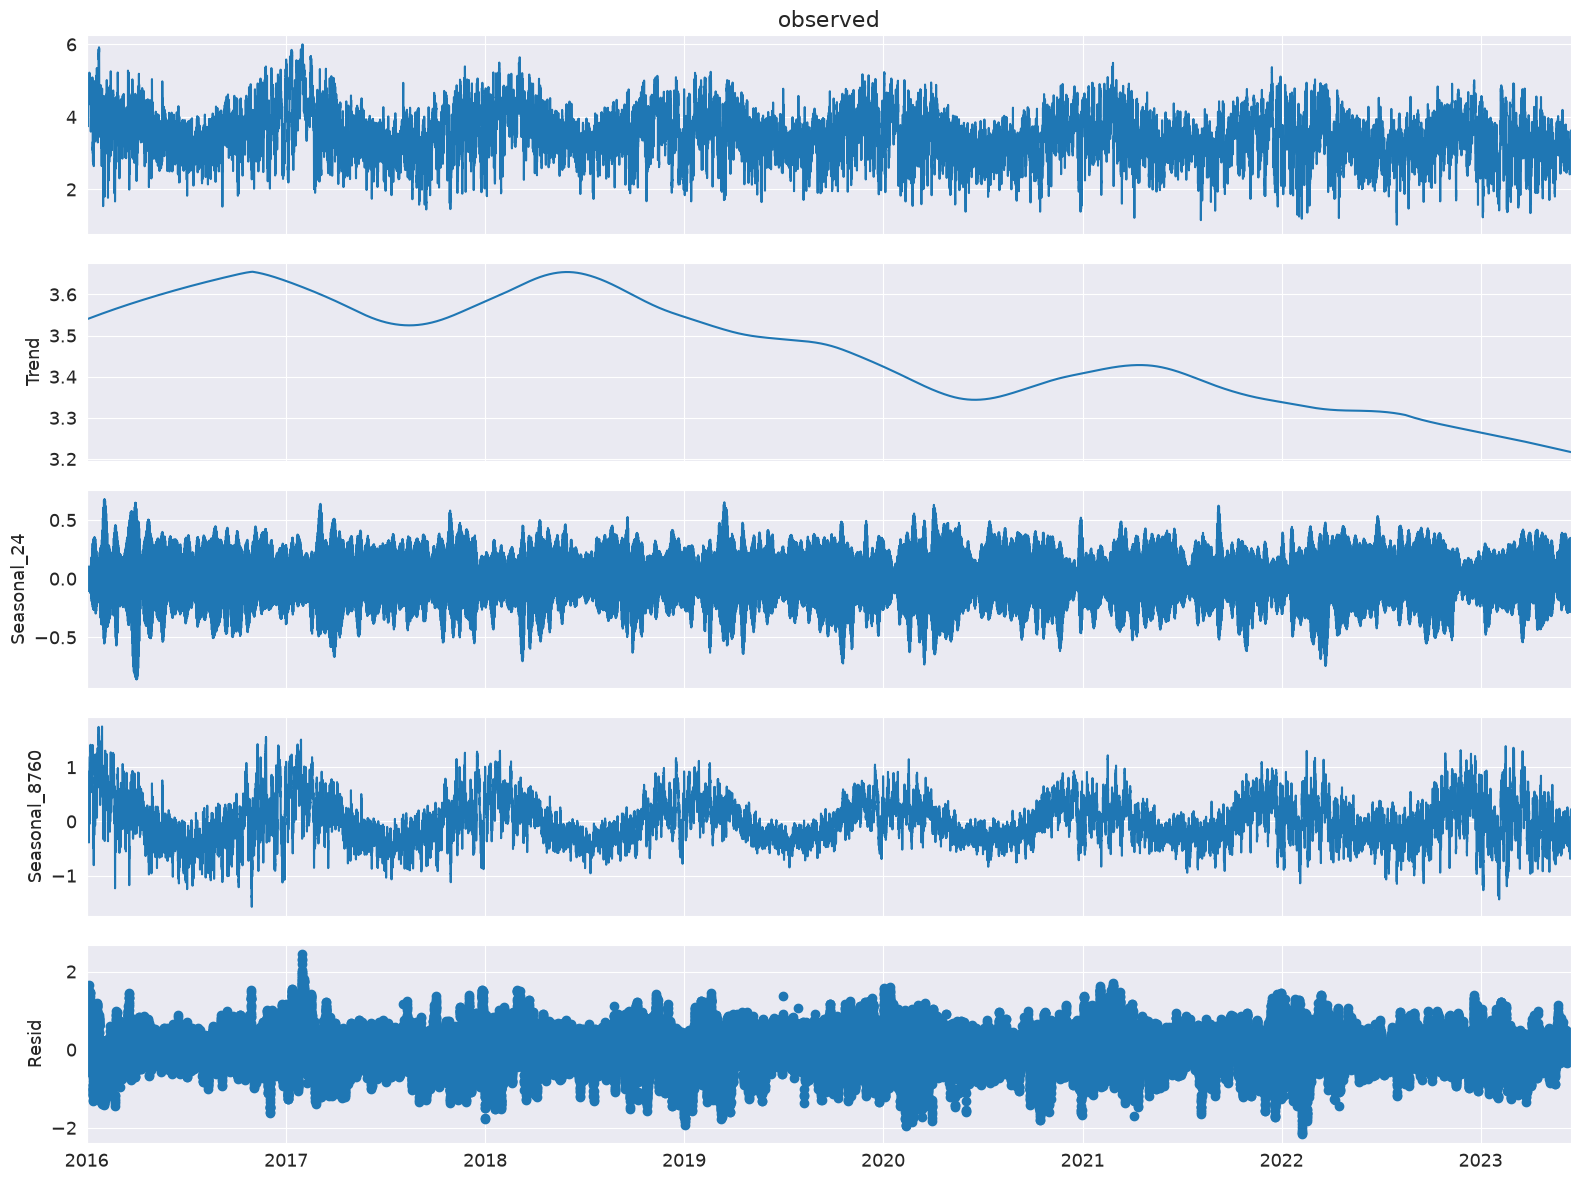

In [6]:
ax = res.plot()

### Observations
Taking the logharitm helped to smothe the outliers, we still see that the trend component iis going down over time.
We see that model catched the yearly component of TS.
Yearly period has values that are varing way more in the years 2016-2017 than in the years 2023!

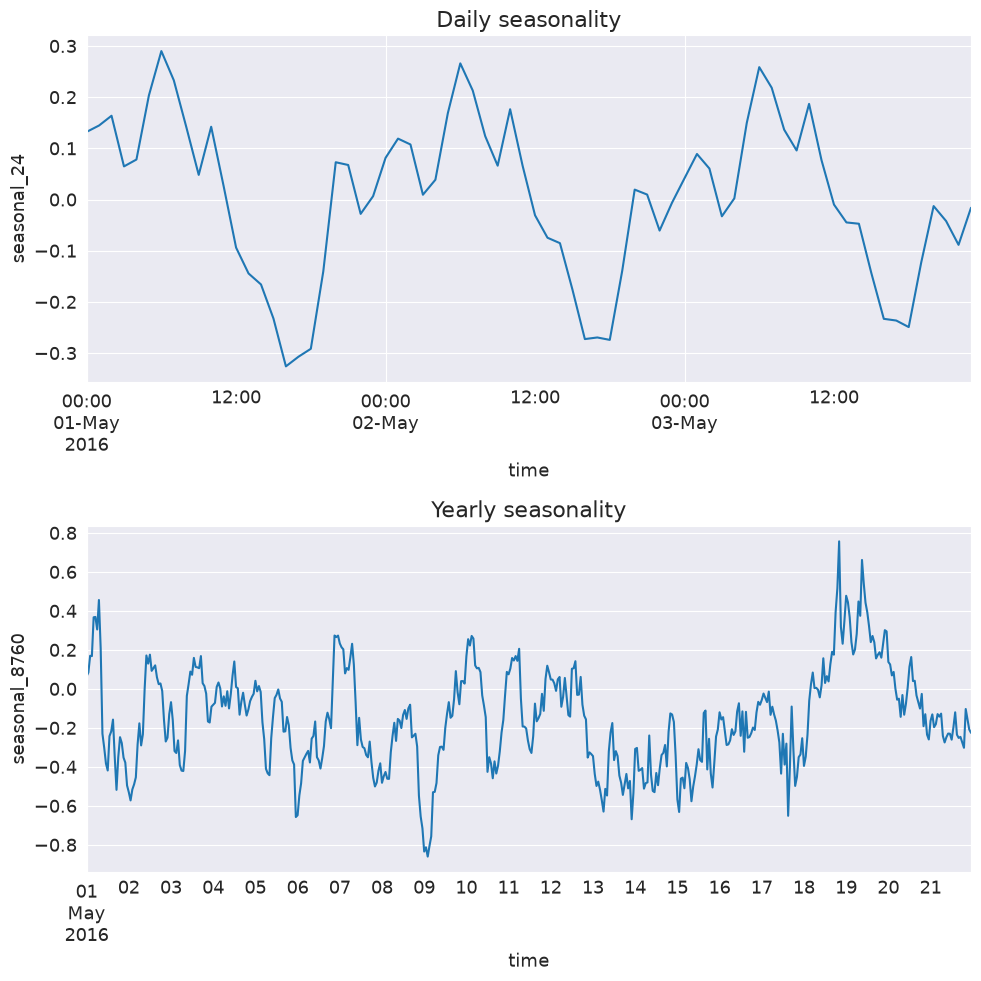

In [7]:
fig, ax = pyplot.subplots(nrows=2, figsize=[10, 10])
mask = res.seasonal.index.month == 5
res.seasonal[mask]["seasonal_24"].iloc[: 24 * 3].plot(ax=ax[0])
ax[0].set_ylabel("seasonal_24")
ax[0].set_title("Daily seasonality")

res.seasonal[mask]["seasonal_8760"].iloc[: 24 * 7 * 3].plot(ax=ax[1])
ax[1].set_ylabel("seasonal_8760")
ax[1].set_title("Yearly seasonality")


pyplot.tight_layout()

### Observations
Daily seasionality is well catched. It proves again that daily seasonality can be crutial for air polution 
levels prediction.
Also comparing the earlies years and the newest years show that over time PM10 values in Krakow seem to be 
not be that high in the newest years (so their variance is probably lower in the recent years).
**The structure of the data changes significantly over time and this may be an important information for deciding what and how to train the model.**


---